# Titanic: classificazione con Kumo Tabular (ONNX)

Predizione di `Survived` con il modello tabulare di NVIDIA, eseguito con **ONNX Runtime** (niente torch).
Con solo 156 righe non c'è un test set fisso: tutto si valuta con **cross-validation stratificata a 5 fold**
e prediction *out-of-fold* (ogni passeggero viene predetto una volta, da un modello che non ha visto la sua etichetta).

1. **Parte 1:** Kumo sulle feature originali, con metriche e grafici (`scikit-learn`, `matplotlib`).
2. **Parte 2:** `Pipeline` sklearn con feature engineering (`ColumnTransformer`) + Kumo, confrontata con la stessa pipeline
   con una `RandomForest`, sugli stessi fold. Nel wrapper sklearn `KumoClassifier`, `fit` non addestra niente: chiama solo `set_context`.

In [ ]:
!pip install -q onnxruntime

## 1. Dati

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

path = 'https://frenzy86.s3.eu-west-2.amazonaws.com/fav/tecno/titanic.csv'

df = pd.read_csv(path, sep='\t')
#df = pd.read_csv(path,)
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
151,152,1,1,"Pears, Mrs. Thomas (Edith Wearne)",female,22.0,1,0,113776,66.6000,C2,S
152,153,0,3,"Meo, Mr. Alfonzo",male,55.5,0,0,A.5. 11206,8.0500,NaN,S
153,154,0,3,"van Billiard, Mr. Austin Blyler",male,40.5,0,2,A/5. 851,14.5000,NaN,S
154,155,0,3,"Olsen, Mr. Ole Martin",male,NaN,0,0,Fa 265302,7.3125,NaN,S


## 2. Modulo `kumo_onnx.py` e download del modello `.onnx` (classificazione)

Tutto il codice del modello (download, preprocessing, classe `KumoTabularONNX`) è nel modulo [`kumo_onnx.py`](https://github.com/Frenz86/kumo/blob/main/kumo_onnx.py) su GitHub: il notebook lo scarica e lo importa direttamente, senza bisogno del file in locale.

Il file `.onnx` (~116 MB) viene salvato in `models/`

In [2]:
import sys, types, urllib.request
from pathlib import Path

# Modulo scaricato da GitHub e caricato in memoria (non serve kumo_onnx.py nella cartella)
KUMO_URL = "https://raw.githubusercontent.com/Frenz86/kumo/main/kumo_onnx.py"
codice = urllib.request.urlopen(KUMO_URL).read().decode("utf-8")
kumo_onnx = types.ModuleType("kumo_onnx")
kumo_onnx.__file__ = str(Path.cwd() / "kumo_onnx.py")  # così il modello .onnx finisce in ./models
exec(compile(codice, KUMO_URL, "exec"), kumo_onnx.__dict__)
sys.modules["kumo_onnx"] = kumo_onnx

from kumo_onnx import KumoClassifier, KumoTabularONNX, download_model

print("classification ->", download_model("classification"))

small_classification.onnx: 116/116 MB
classification -> C:\Users\danie\Il mio Drive\Lesson\IFOA\ML-AI_8\21_Mod_in_context\Kumo\models\small_classification.onnx


# Parte 1: Kumo sulle feature originali

## 3. Feature e fold della cross-validation

Tolgo le colonne identificative (`PassengerId`, `Name`, `Ticket`) e `Cabin` (80% mancante).
`Sex` ed `Embarked` sono testo: Kumo le tratta in automatico come categoriche, e gestisce da solo i valori mancanti di `Age`.

I 5 fold sono **stratificati** (`StratifiedKFold`): ogni fold ha la stessa percentuale di sopravvissuti del dataset intero.
Gli stessi fold si usano per tutti i modelli del notebook, così i confronti sono sugli stessi passeggeri.

In [3]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedKFold

TARGET = "Survived"
DROP = ["PassengerId", "Name", "Ticket", "Cabin"]

X = df.drop(columns=[TARGET] + DROP)
y = df[TARGET].to_numpy()

folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=0).split(X, y))  # [(indici contesto, indici test), ...]

print(f"{len(y)} righe, feature = {list(X.columns)}")
print(f"sopravvissuti nel dataset: {y.mean():.1%}")
for f, (tr, te) in enumerate(folds):
    print(f"fold {f}: contesto = {len(tr)} righe, test = {len(te)} righe, sopravvissuti nel test = {y[te].mean():.1%}")

156 righe, feature = ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']
sopravvissuti nel dataset: 34.6%
fold 0: contesto = 124 righe, test = 32 righe, sopravvissuti nel test = 34.4%
fold 1: contesto = 125 righe, test = 31 righe, sopravvissuti nel test = 32.3%
fold 2: contesto = 125 righe, test = 31 righe, sopravvissuti nel test = 35.5%
fold 3: contesto = 125 righe, test = 31 righe, sopravvissuti nel test = 35.5%
fold 4: contesto = 125 righe, test = 31 righe, sopravvissuti nel test = 35.5%


## 4. Prediction out-of-fold

Kumo non si addestra: i pesi del modello `.onnx` sono pre-addestrati e restano fissi (*in-context learning*).
`set_context()` memorizza solo le righe etichettate; in `predict` il modello le legge insieme alle righe da predire,
come gli esempi in un prompt, e da lì deduce le risposte.

Per ogni fold: le altre 4/5 delle righe fanno da contesto, le righe del fold vengono predette.
Alla fine ogni passeggero ha una probabilità calcolata **senza** che la sua etichetta fosse nel contesto.

In [4]:
def kumo_oof(model, X, y, folds):
    # Probabilità out-of-fold [n_righe, n_classi]: per ogni fold il modello riceve come contesto
    # le altre righe (set_context sostituisce il contesto precedente) e predice quelle del fold
    proba = np.zeros((len(y), len(np.unique(y))))
    for tr, te in folds:
        model.set_context(X.iloc[tr], y[tr])
        proba[te] = model.predict_proba(X.iloc[te])
    return proba


kumo = KumoTabularONNX("classification", n_estimators=8, seed=0)
proba = kumo_oof(kumo, X, y, folds)
labels = kumo.classes_
y_pred = labels[proba.argmax(axis=1)]          # classe più probabile
score = proba[:, list(labels).index(1)]        # P(Survived = 1), serve per la ROC
print(f"classi = {labels.tolist()}")

pd.DataFrame({"vero": y, "predetto": y_pred, "P(sopravvive)": score.round(3)}).head(10)

classi = [0, 1]


,vero,predetto,P(sopravvive)
0,0,0,0.175
1,1,1,0.799
2,1,1,0.706
3,1,1,0.613
4,0,0,0.083
5,0,0,0.168
6,0,0,0.148
7,0,0,0.125
8,1,1,0.690
9,1,1,0.854


## 5. Metriche: accuracy, classification report, ROC/AUC

Le metriche sono calcolate su tutte le 156 prediction out-of-fold; l'AUC per fold mostra quanto varia il risultato da un fold all'altro.

In [5]:
def fold_aucs(y, score, folds):
    # AUC calcolata separatamente su ogni fold
    return np.array([roc_auc_score(y[te], score[te]) for _, te in folds])


cm = confusion_matrix(y, y_pred, labels=labels)  # righe = vero, colonne = predetto
fpr, tpr, _ = roc_curve(y, score)
roc_auc = roc_auc_score(y, score)
aucs = fold_aucs(y, score, folds)

print(f"accuracy = {(y_pred == y).mean():.4f}   ROC AUC (tutte le righe) = {roc_auc:.4f}")
print(f"ROC AUC per fold = {aucs.round(3)}   media = {aucs.mean():.4f} ± {aucs.std():.4f}\n")
print("confusion matrix (righe = vero, colonne = predetto):\n", cm, "\n")
print(classification_report(y, y_pred))

accuracy = 0.8333   ROC AUC (tutte le righe) = 0.8477
ROC AUC per fold = [0.896 0.767 0.845 0.855 0.886]   media = 0.8498 ± 0.0457

confusion matrix (righe = vero, colonne = predetto):
 [[92 10]
 [16 38]] 

              precision    recall  f1-score   support

           0       0.85      0.90      0.88       102
           1       0.79      0.70      0.75        54

    accuracy                           0.83       156
   macro avg       0.82      0.80      0.81       156
weighted avg       0.83      0.83      0.83       156



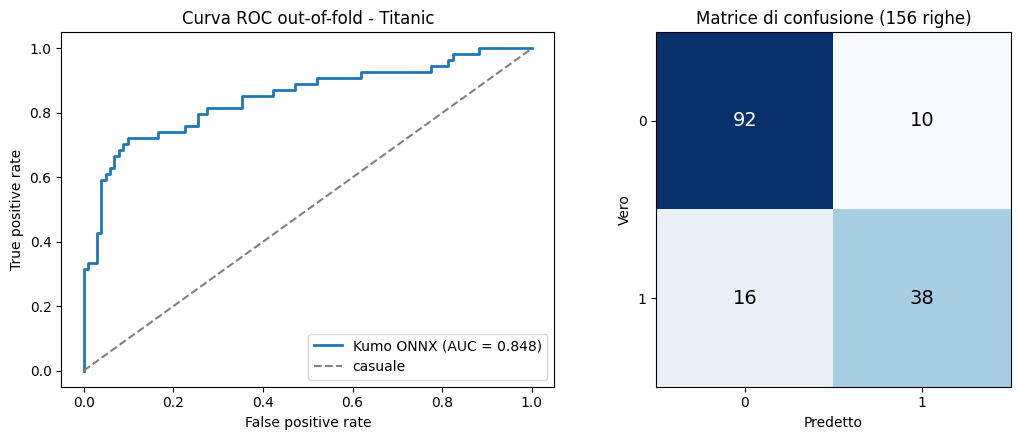

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5))

ax1.plot(fpr, tpr, lw=2, label=f"Kumo ONNX (AUC = {roc_auc:.3f})")
ax1.plot([0, 1], [0, 1], "--", color="gray", label="casuale")
ax1.set(xlabel="False positive rate", ylabel="True positive rate", title="Curva ROC out-of-fold - Titanic")
ax1.legend(loc="lower right")

ax2.imshow(cm, cmap="Blues")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        ax2.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=14)
ax2.set(xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=labels, yticklabels=labels,
        xlabel="Predetto", ylabel="Vero", title="Matrice di confusione (156 righe)")
plt.tight_layout()
plt.show()

# Parte 2: Pipeline sklearn con feature engineering

## 6. Feature engineering come `ColumnTransformer` + Kumo

Ogni nuova feature è un `FunctionTransformer` che lavora solo sulle colonne che gli servono:

- `Title` estratto da `Name` (Mr, Mrs, Miss, Master, Rare);
- `FamilySize` = `SibSp` + `Parch` + 1;
- `HasCabin` = 1 se `Cabin` è presente.

Le colonne originali utili passano invariate (`passthrough`), le altre (`PassengerId`, `Name`, `Ticket`, `Cabin`) vengono scartate.
Con `set_output(transform="pandas")` l'uscita resta un DataFrame con nomi e tipi delle colonne, così Kumo riconosce le categoriche.

L'ultimo step è `KumoClassifier` (in `kumo_onnx.py`): la `Pipeline` chiama `fit`, che per Kumo vuol dire solo `set_context`.
Lo stesso step `features` si riusa nella pipeline della RandomForest.

In [7]:
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer


def extract_title(data):
    title = data["Name"].str.extract(r",\s*([^.]+)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    return title.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), "Rare").to_frame("Title")


def family_size(data):
    return (data["SibSp"] + data["Parch"] + 1).to_frame("FamilySize")


def has_cabin(data):
    return data["Cabin"].notna().astype(int).to_frame("HasCabin")


def new_feature(func, name):
    return FunctionTransformer(func, feature_names_out=lambda transformer, cols: [name])


features = ColumnTransformer([
                            ("keep", "passthrough", ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]),
                            ("title", new_feature(extract_title, "Title"), ["Name"]),
                            ("family", new_feature(family_size, "FamilySize"), ["SibSp", "Parch"]),
                            ("cabin", new_feature(has_cabin, "HasCabin"), ["Cabin"]),
                            ], remainder="drop", verbose_feature_names_out=False).set_output(transform="pandas")

kumo_pipe = Pipeline([
                    ("features", features),
                    ("classifier", KumoClassifier(n_estimators=8, seed=0)),
                    ])

X_raw = df.drop(columns=[TARGET])

# Esempio: contesto = righe fuori dal fold 0, predict sulle righe grezze del fold 0
tr, te = folds[0]
kumo_pipe.fit(X_raw.iloc[tr], y[tr])  # fit = set_context, nessun training
pd.DataFrame({"Name": X_raw["Name"].iloc[te], "vero": y[te], "predetto": kumo_pipe.predict(X_raw.iloc[te])}).head(10)

,Name,vero,predetto
2,"Heikkinen, Miss. Laina",1,1
5,"Moran, Mr. James",0,0
9,"Nasser, Mrs. Nicholas (Adele Achem)",1,1
13,"Andersson, Mr. Anders Johan",0,0
27,"Fortune, Mr. Charles Alexander",0,0
29,"Todoroff, Mr. Lalio",0,0
32,"Glynn, Miss. Mary Agatha",1,1
37,"Cann, Mr. Ernest Charles",0,0
41,"Turpin, Mrs. William John Robert (Dorothy Ann ...",0,1
48,"Samaan, Mr. Youssef",0,0


In [8]:
proba_fe = cross_val_predict(kumo_pipe, X_raw, y, cv=folds, method="predict_proba")  # la pipeline riceve i dati grezzi
score_fe = proba_fe[:, list(labels).index(1)]
pred_fe = labels[proba_fe.argmax(axis=1)]
aucs_fe = fold_aucs(y, score_fe, folds)
print(f"Kumo + feature engineering   ROC AUC = {roc_auc_score(y, score_fe):.4f}   per fold = {aucs_fe.mean():.4f} ± {aucs_fe.std():.4f}\n")
print(classification_report(y, pred_fe))

Kumo + feature engineering   ROC AUC = 0.8631   per fold = 0.8650 ± 0.0558

              precision    recall  f1-score   support

           0       0.85      0.92      0.88       102
           1       0.82      0.69      0.75        54

    accuracy                           0.84       156
   macro avg       0.83      0.80      0.82       156
weighted avg       0.84      0.84      0.84       156



## 7. Confronto con una pipeline classica (RandomForest)

La RandomForest ha bisogno di imputazione e one-hot encoding; Kumo no, gestisce da solo testo e valori mancanti.
Lo step `features` è lo stesso della pipeline Kumo. `cross_val_predict` addestra la pipeline su ogni fold (qui il training c'è davvero) e restituisce le prediction out-of-fold.

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

num_cols = ["Pclass", "Age", "SibSp", "Parch", "Fare", "FamilySize", "HasCabin"]
cat_cols = ["Sex", "Embarked", "Title"]

rf_pipe = Pipeline([
                    ("features", features),
                    ("prep", ColumnTransformer([
                    ("num", SimpleImputer(strategy="median"), num_cols),
                    ("cat", make_pipeline(SimpleImputer(strategy="most_frequent"), OneHotEncoder(handle_unknown="ignore")), cat_cols),])),
                    ("classifier", RandomForestClassifier(n_estimators=300, random_state=0)),
])
proba_rf = cross_val_predict(rf_pipe, X_raw, y, cv=folds, method="predict_proba")
score_rf = proba_rf[:, 1]
pred_rf = labels[proba_rf.argmax(axis=1)]
aucs_rf = fold_aucs(y, score_rf, folds)
print(f"Pipeline RandomForest   ROC AUC = {roc_auc_score(y, score_rf):.4f}   per fold = {aucs_rf.mean():.4f} ± {aucs_rf.std():.4f}\n")
print(classification_report(y, pred_rf))

Pipeline RandomForest   ROC AUC = 0.8444   per fold = 0.8396 ± 0.0707

              precision    recall  f1-score   support

           0       0.81      0.87      0.84       102
           1       0.72      0.61      0.66        54

    accuracy                           0.78       156
   macro avg       0.76      0.74      0.75       156
weighted avg       0.78      0.78      0.78       156



## 8. Riepilogo

Stessi fold e stesse 156 righe per tutti i modelli. La colonna ± è la deviazione standard dell'AUC tra i fold:
se gli intervalli si sovrappongono molto, la differenza tra due modelli non è affidabile con così pochi dati.

modello                 accuracy   ROC AUC        AUC per fold
Kumo                      0.8333    0.8477      0.8498 ± 0.0457
Kumo + feature eng.       0.8397    0.8631      0.8650 ± 0.0558
RandomForest              0.7821    0.8444      0.8396 ± 0.0707


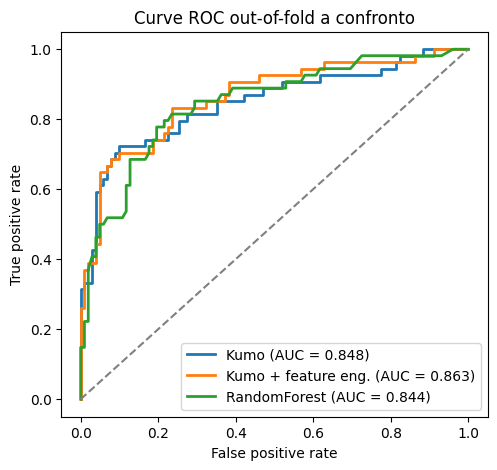

In [10]:
results = [("Kumo", score, y_pred, aucs),
           ("Kumo + feature eng.", score_fe, pred_fe, aucs_fe),
           ("RandomForest", score_rf, pred_rf, aucs_rf)]

print(f"{'modello':22s}{'accuracy':>10}{'ROC AUC':>10}{'AUC per fold':>20}")
for name, s, p, a in results:
    print(f"{name:22s}{(p == y).mean():>10.4f}{roc_auc_score(y, s):>10.4f}{a.mean():>12.4f} ± {a.std():.4f}")

plt.figure(figsize=(5.5, 5))
for name, s, _, _ in results:
    f, t, _ = roc_curve(y, s)
    plt.plot(f, t, lw=2, label=f"{name} (AUC = {roc_auc_score(y, s):.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Curve ROC out-of-fold a confronto")
plt.legend(loc="lower right")
plt.show()